# Model 2: trained embedding-based collaborative filtering

We predict explicit MovieLens ratings using TensorFlow/Keras. Unlike notebook 02, which compares predefined genre features, this model **learns user–movie relationships from ratings**. Genres and titles are used only to label recommendation tables. `movieId`, never title, identifies a movie.

This is neural collaborative filtering through trainable embeddings (biased matrix factorization). It is deliberately simple: no dense hidden layers, hybrid model, or application UI. Experiment 1 outputs below are preserved historical results. Run All now skips its retraining and all legacy test/demo/report execution by default, then runs Experiments 2 and 3 and stops at validation comparison.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print({"Python": platform.python_version(), "TensorFlow": tf.__version__,
       "Keras": keras.__version__, "NumPy": np.__version__, "Pandas": pd.__version__})
# Keep the original experiment and test-related work paused.
RUN_EXPERIMENT_1 = False
RUN_LEGACY_TEST_AND_DEMOS = False


{'Python': '3.12.8', 'TensorFlow': '2.21.0', 'Keras': '3.15.1', 'NumPy': '2.5.4', 'Pandas': '3.0.6'}


## 1. Load and briefly inspect the existing data

Use processed movies and prefer processed ratings if present. In the inspected project only movies were processed, so ratings are read directly from `data/raw/ratings.csv`. No input files are rewritten. We check identifiers and rating validity rather than repeat the exploratory analysis.

In [2]:
project_root = Path.cwd()
if not (project_root / "data").is_dir():
    project_root = project_root.parent
movies_path = project_root / "data/processed/movies_processed.csv"
ratings_path = project_root / "data/processed/ratings_processed.csv"
if not ratings_path.exists():
    ratings_path = project_root / "data/raw/ratings.csv"

movies = pd.read_csv(movies_path)[["movieId", "title", "genres"]]
ratings = pd.read_csv(ratings_path)[["userId", "movieId", "rating"]]
assert movies["movieId"].is_unique, "movieId must be unique."
assert not movies.isna().any().any()
assert not ratings.isna().any().any()
assert not ratings.duplicated(["userId", "movieId"]).any(), "Review repeated user/movie ratings before splitting."
assert np.isfinite(ratings["rating"]).all()
assert ratings["rating"].between(0.5, 5.0).all(), "Expected MovieLens ratings from 0.5 to 5.0."
assert ratings["movieId"].isin(movies["movieId"]).all()
for column in ["userId", "movieId"]:
    assert (ratings[column] % 1 == 0).all(), "IDs must be integers."
    ratings[column] = ratings[column].astype("int64")

print("Movies:", movies_path.relative_to(project_root))
print("Ratings:", ratings_path.relative_to(project_root))
print(f"{len(ratings):,} ratings, {ratings.userId.nunique():,} users, "
      f"{ratings.movieId.nunique():,} rated movies; {len(movies):,} catalog movies")
display(ratings.head())
display(movies.head())

Movies: data/processed/movies_processed.csv
Ratings: data/raw/ratings.csv
100,836 ratings, 610 users, 9,724 rated movies; 9,742 catalog movies


,userId,movieId,rating
0,1,1,4.0
1,1,3,4.0
2,1,6,4.0
3,1,47,5.0
4,1,50,5.0


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 2. Split interactions, then encode training IDs

An embedding is a lookup table, so its inputs must be contiguous integers `0, 1, …, n−1`. Raw user/movie IDs can have gaps and are identifiers, not numerical measurements. Separate dictionaries map each training ID to its embedding row.

A seeded random split reserves **15% for testing**, then splits the remaining 85% to produce approximately **70% training / 15% validation / 15% test**. Only training ratings update parameters. Validation selects the stopping epoch; test ratings are evaluated once after training. This random split measures held-out rating prediction, not future-time performance.

Mappings are fitted on training IDs only. Validation/test interactions with a user or movie absent from training are counted separately and excluded from **warm-start** evaluation; untrained embeddings would not give a fair prediction. Their exclusion must be reported with the metrics, not hidden.

In [3]:
TEST_FRACTION = 0.15
VALIDATION_FRACTION = 0.15
train_validation, test_raw = train_test_split(
    ratings, test_size=TEST_FRACTION, random_state=SEED
)
train, validation_raw = train_test_split(
    train_validation, test_size=VALIDATION_FRACTION / (1 - TEST_FRACTION),
    random_state=SEED
)
train = train.copy()
user_to_index = {user_id: index for index, user_id in enumerate(sorted(train.userId.unique()))}
movie_to_index = {movie_id: index for index, movie_id in enumerate(sorted(train.movieId.unique()))}

def known_interactions(frame):
    return frame[frame.userId.isin(user_to_index) & frame.movieId.isin(movie_to_index)].copy()

validation = known_interactions(validation_raw)
test = known_interactions(test_raw)
split_summary = pd.DataFrame([
    {"partition": "train", "original_rows": len(train), "evaluated_or_trained_rows": len(train)},
    {"partition": "validation", "original_rows": len(validation_raw), "evaluated_or_trained_rows": len(validation)},
    {"partition": "test", "original_rows": len(test_raw), "evaluated_or_trained_rows": len(test)},
])
split_summary["cold_start_rows_excluded"] = split_summary.original_rows - split_summary.evaluated_or_trained_rows
split_summary["original_fraction"] = split_summary.original_rows / len(ratings)
display(split_summary)
assert len(train) and len(validation) and len(test)
assert set(train.index).isdisjoint(validation_raw.index)
assert set(train.index).isdisjoint(test_raw.index)
assert set(validation_raw.index).isdisjoint(test_raw.index)
print("Training user/movie counts:", len(user_to_index), len(movie_to_index))
display(pd.DataFrame(list(movie_to_index.items())[:5], columns=["movieId", "movie_index"]))

,partition,original_rows,evaluated_or_trained_rows,cold_start_rows_excluded,original_fraction
0,train,70584,70584,0,0.699988
1,validation,15126,14443,683,0.150006
2,test,15126,14466,660,0.150006


Training user/movie counts: 610 8576


,movieId,movie_index
0,1,0
1,2,1
2,3,2
3,4,3
4,5,4


In [4]:
def encode_inputs(frame):
    return {
        "user": frame["userId"].map(user_to_index).to_numpy(dtype="int32").reshape(-1, 1),
        "movie": frame["movieId"].map(movie_to_index).to_numpy(dtype="int32").reshape(-1, 1),
    }

train_inputs = encode_inputs(train)
validation_inputs = encode_inputs(validation)
test_inputs = encode_inputs(test)
y_train = train.rating.to_numpy(dtype="float32").reshape(-1, 1)
y_validation = validation.rating.to_numpy(dtype="float32").reshape(-1, 1)
y_test = test.rating.to_numpy(dtype="float32").reshape(-1, 1)
print("Input shapes:", {name: values.shape for name, values in train_inputs.items()})
print("Target shape:", y_train.shape)

Input shapes: {'user': (70584, 1), 'movie': (70584, 1)}
Target shape: (70584, 1)


## 3. Model and initial hyperparameters

An **embedding** is a short list of learned numbers representing an ID. User embeddings describe rating patterns/preferences; movie embeddings describe patterns of users who rate each movie. Dimensions are learned latent factors, not named genres.

The **dot product** sums products of corresponding factors, so aligned user/movie factors increase predicted compatibility. A **user bias** captures a user's tendency to rate higher or lower; a **movie bias** captures a movie's generally higher or lower ratings. A fixed training-set mean anchors predictions to the rating scale:

`predicted rating = training mean + user bias + movie bias + dot(user factors, movie factors)`

Initial settings: 32 embedding dimensions, Adam learning rate 0.005, batch size 256, at most 30 epochs, and small L2 regularization of 0.000001 on factors and biases. Early stopping monitors validation MAE with patience 4 and restores the best weights. The loss is MSE; we track MAE. These are one reasonable starting configuration, not the result of a search.

Output is linear, so predictions may extend beyond the 0.5–5 scale. Training/validation history and archived experiment metrics use raw outputs. Final evaluation and recommendations now clip predictions to [0.5, 5.0] after inference; this does not retrain or change the saved network.

In [5]:
EMBEDDING_DIMENSION = 32
LEARNING_RATE = 0.005
BATCH_SIZE = 256
MAX_EPOCHS = 30
L2_STRENGTH = 0.000001
PATIENCE = 4
training_mean = float(y_train.mean())

def build_model(embedding_dimension, learning_rate):
    """Build and compile fresh seeded factors, biases, and Adam state."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    regularizer = keras.regularizers.l2(L2_STRENGTH)
    user_input = keras.Input(shape=(1,), dtype="int32", name="user")
    movie_input = keras.Input(shape=(1,), dtype="int32", name="movie")
    user_factors = keras.layers.Flatten()(keras.layers.Embedding(
        len(user_to_index), embedding_dimension, embeddings_regularizer=regularizer,
        name="user_embedding")(user_input))
    movie_factors = keras.layers.Flatten()(keras.layers.Embedding(
        len(movie_to_index), embedding_dimension, embeddings_regularizer=regularizer,
        name="movie_embedding")(movie_input))
    user_bias = keras.layers.Flatten()(keras.layers.Embedding(
        len(user_to_index), 1, embeddings_initializer="zeros",
        embeddings_regularizer=regularizer, name="user_bias")(user_input))
    movie_bias = keras.layers.Flatten()(keras.layers.Embedding(
        len(movie_to_index), 1, embeddings_initializer="zeros",
        embeddings_regularizer=regularizer, name="movie_bias")(movie_input))
    compatibility = keras.layers.Dot(axes=1)([user_factors, movie_factors])
    rating_offset = keras.layers.Add()([compatibility, user_bias, movie_bias])
    prediction = keras.layers.Rescaling(scale=1.0, offset=training_mean)(rating_offset)
    model = keras.Model(inputs={"user": user_input, "movie": movie_input}, outputs=prediction)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="mse", metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
    return model

if RUN_EXPERIMENT_1:
    model = build_model(EMBEDDING_DIMENSION, LEARNING_RATE)
    model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_embedding      │ (None, 1, 32)     │     19,520 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie_embedding     │ (None, 1, 32)     │    274,432 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ user_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ movie_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_bias           │ (None, 1, 1)      │        610 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie_bias          │ (None, 1, 1)      │      8,576 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1)         │          0 │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 1)         │          0 │ user_bias[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 1)         │          0 │ movie_bias[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1)         │          0 │ dot[0][0],        │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 1)         │          0 │ add[0][0]         │
│ (Rescaling)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 303,138 (1.16 MB)

 Trainable params: 303,138 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train on the training partition

The small dataset helper batches inputs and keeps TensorFlow's data-loading thread pool small for a laptop. Training data are shuffled reproducibly each epoch; validation and test data retain order. `model.fit()` actually learns the embeddings and biases. History stores the observed epoch metrics; no results are prefilled.

In [6]:
def make_dataset(inputs, targets, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((inputs, targets))
    if training:
        dataset = dataset.shuffle(len(targets), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return dataset.with_options(options).prefetch(1)

# Recovered from Experiment 1's saved table (six-decimal display precision).
experiment_1_saved_history = {'loss': [0.904468, 0.582661, 0.32647, 0.212806, 0.161542, 0.133662], 'mae': [0.743669, 0.572927, 0.419171, 0.33339, 0.286544, 0.256033], 'val_loss': [0.772833, 0.758456, 0.809127, 0.858192, 0.895764, 0.932781], 'val_mae': [0.674776, 0.665013, 0.686893, 0.707635, 0.722372, 0.738231]}

if RUN_EXPERIMENT_1:
    train_dataset = make_dataset(train_inputs, y_train, training=True)
    validation_dataset = make_dataset(validation_inputs, y_validation)
    test_dataset = make_dataset(test_inputs, y_test)
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_mae", patience=PATIENCE, restore_best_weights=True, mode="min"
    )
    history = model.fit(train_dataset, validation_data=validation_dataset,
                        epochs=MAX_EPOCHS, callbacks=[early_stopping], shuffle=False, verbose=2)
    history_frame = pd.DataFrame(history.history)
    history_frame.index = pd.RangeIndex(1, len(history_frame) + 1, name="epoch")
    display(history_frame)
    best_epoch = int(history_frame.val_mae.idxmin())
    print(f"Completed {len(history_frame)} epochs; restored weights from epoch {best_epoch}.")
else:
    history_frame = pd.DataFrame(experiment_1_saved_history)
    history_frame.index = pd.RangeIndex(1, len(history_frame) + 1, name="epoch")
    best_epoch = int(history_frame.val_mae.idxmin())
    print("Experiment 1 not retrained; using its archived six-epoch history.")


Epoch 1/30


276/276 - 1s - 4ms/step - loss: 0.9045 - mae: 0.7437 - val_loss: 0.7728 - val_mae: 0.6748


Epoch 2/30


276/276 - 1s - 2ms/step - loss: 0.5827 - mae: 0.5729 - val_loss: 0.7585 - val_mae: 0.6650


Epoch 3/30


276/276 - 1s - 2ms/step - loss: 0.3265 - mae: 0.4192 - val_loss: 0.8091 - val_mae: 0.6869


... (4 outputs left out)

Epoch 6/30


276/276 - 1s - 2ms/step - loss: 0.1337 - mae: 0.2560 - val_loss: 0.9328 - val_mae: 0.7382


,loss,mae,val_loss,val_mae
epoch,,,,
1,0.904468,0.743669,0.772833,0.674776
2,0.582661,0.572927,0.758456,0.665013
3,0.326470,0.419171,0.809127,0.686893
4,0.212806,0.333390,0.858192,0.707635
5,0.161542,0.286544,0.895764,0.722372
6,0.133662,0.256033,0.932781,0.738231


Completed 6 epochs; restored weights from epoch 2.


## 5. Inspect training and validation curves

Falling training loss means the network fits observed training ratings better. Falling validation error suggests that improvement also transfers to held-out known user/movie pairs. If training error falls while validation error rises, that is evidence of overfitting. Early stopping restores the epoch with the lowest validation MAE.

Loss includes the MSE objective **plus L2 penalties**, so it is not exactly pure prediction MSE. MAE is reported in rating points and is easier to interpret. The code below describes the observed curves using actual history, rather than claiming improvement in advance.

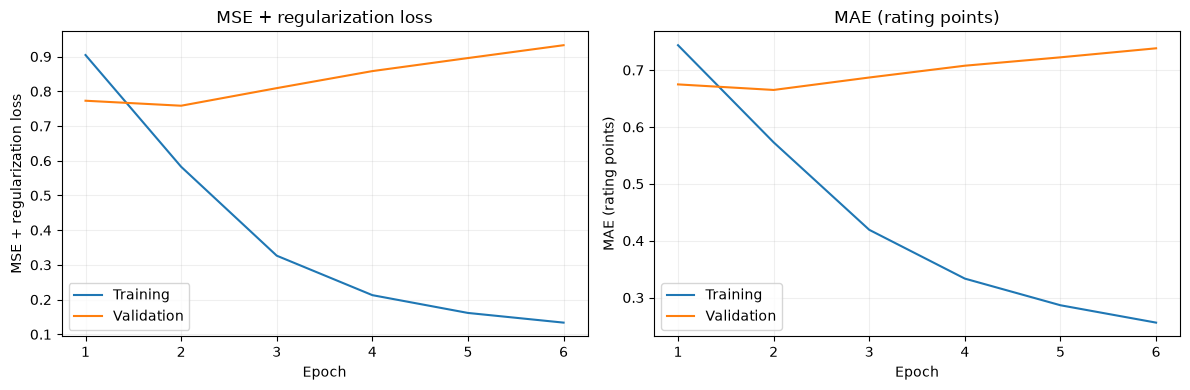

Training MAE changed from 0.7437 to 0.2560; validation MAE changed from 0.6748 to 0.7382. The lowest validation MAE was 0.6650 at epoch 2. After that epoch, training MAE decreased while validation MAE rose, consistent with overfitting.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric, title in zip(axes, ["loss", "mae"], ["MSE + regularization loss", "MAE (rating points)"]):
    axis.plot(history_frame.index, history_frame[metric], label="Training")
    axis.plot(history_frame.index, history_frame["val_" + metric], label="Validation")
    axis.set(xlabel="Epoch", ylabel=title, title=title)
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

first = history_frame.iloc[0]
last = history_frame.iloc[-1]
behavior = (
    f"Training MAE changed from {first.mae:.4f} to {last.mae:.4f}; "
    f"validation MAE changed from {first.val_mae:.4f} to {last.val_mae:.4f}. "
    f"The lowest validation MAE was {history_frame.loc[best_epoch, 'val_mae']:.4f} "
    f"at epoch {best_epoch}. "
)
if last.mae < history_frame.loc[best_epoch, "mae"] and last.val_mae > history_frame.loc[best_epoch, "val_mae"]:
    behavior += "After that epoch, training MAE decreased while validation MAE rose, consistent with overfitting."
else:
    behavior += "Inspect the curves for the size of the train/validation gap; one run does not establish generalization."
print(behavior)

## 6. Evaluate once on held-out warm-start test ratings

**MAE** is the average absolute difference between predicted and actual ratings. **RMSE** is the square root of the mean squared difference; it penalizes large errors more strongly. Both are in rating points, not accuracy percentages. MSE is in squared rating points.

`model.evaluate()` supplies the Keras MAE and regularized loss. We also calculate pure MAE/MSE/RMSE from test predictions. A training-mean-only predictor gives a simple reference on the same test rows; it is not a second trained model. No clipping is applied. These metrics apply only to test interactions with training-known IDs; excluded cold-start rows are shown above.

**Archived Experiment 1 section:** outputs below were produced before this controlled comparison. Test evaluation and related legacy cells are disabled by default. They are not run or used to select the new configuration. The old test set has already been seen; a new untouched holdout would be needed for a strictly independent final claim.


In [8]:
# Historical Experiment 1 output is preserved; execution is paused.
if RUN_LEGACY_TEST_AND_DEMOS:
    test_evaluation = model.evaluate(test_dataset, return_dict=True, verbose=0)
    test_predictions = model.predict(test_dataset, verbose=0).ravel()
    actual_ratings = y_test.ravel()
    assert np.isfinite(test_predictions).all()
    test_mae = float(np.mean(np.abs(test_predictions - actual_ratings)))
    test_mse = float(np.mean((test_predictions - actual_ratings) ** 2))
    test_rmse = float(np.sqrt(test_mse))
    assert np.isclose(test_mae, test_evaluation["mae"], atol=1e-5)
    baseline_mae = float(np.mean(np.abs(training_mean - actual_ratings)))
    baseline_rmse = float(np.sqrt(np.mean((training_mean - actual_ratings) ** 2)))
    display(pd.DataFrame([
        {"predictor": "Trained embeddings", "MAE": test_mae, "RMSE": test_rmse, "MSE": test_mse},
        {"predictor": "Training mean only", "MAE": baseline_mae, "RMSE": baseline_rmse,
         "MSE": baseline_rmse ** 2},
    ]))
    print("Keras evaluation (loss includes regularization):", test_evaluation)
    print(f"Predicted test range: {test_predictions.min():.3f} to {test_predictions.max():.3f}")
else:
    print("Paused: no legacy test evaluation, predictions, demos, or report rerun.")


,predictor,MAE,RMSE,MSE
0,Trained embeddings,0.669208,0.871226,0.759034
1,Training mean only,0.827835,1.041913,1.085582


Keras evaluation (loss includes regularization): {'loss': 0.7648904919624329, 'mae': 0.6692079901695251}
Predicted test range: 0.894 to 5.352


## 7. Compare individual predictions with actual ratings

These are the first ten test examples in the reproducibly shuffled split, not hand-picked successes. Absolute error is the size of each prediction mistake. Joining by movieId preserves distinct records even when titles match.

In [9]:
# Historical Experiment 1 output is preserved; execution is paused.
if RUN_LEGACY_TEST_AND_DEMOS:
    prediction_examples = test[["userId", "movieId", "rating"]].copy()
    prediction_examples = prediction_examples.rename(columns={"rating": "actual_rating"})
    prediction_examples["predicted_rating"] = test_predictions
    prediction_examples["absolute_error"] = np.abs(test_predictions - actual_ratings)
    prediction_examples = prediction_examples.merge(
        movies[["movieId", "title"]], on="movieId", how="left", validate="many_to_one"
    )
    display(prediction_examples[["userId", "movieId", "title", "actual_rating",
                                 "predicted_rating", "absolute_error"]].head(10).round(3))
else:
    print("Paused: no legacy test evaluation, predictions, demos, or report rerun.")


,userId,movieId,title,actual_rating,predicted_rating,absolute_error
0,432,77866,Robin Hood (2010),4.5,3.372,1.128
1,288,474,In the Line of Fire (1993),3.0,3.334,0.334
2,599,4351,Point Break (1991),3.0,2.562,0.438
3,42,2987,Who Framed Roger Rabbit? (1988),4.0,3.942,0.058
4,75,1610,"Hunt for Red October, The (1990)",4.0,3.204,0.796
5,51,177,Lord of Illusions (1995),4.0,3.372,0.628
6,354,51662,300 (2007),3.5,3.910,0.410
7,416,750,Dr. Strangelove or: How I Learned to Stop Worr...,4.5,3.572,0.928
8,438,6503,Charlie's Angels: Full Throttle (2003),0.5,2.901,2.401
9,73,8641,Anchorman: The Legend of Ron Burgundy (2004),3.5,3.981,0.481


## 8. Personalized top-10 recommendations

For an existing training-known user, remove **every movie rated by that user in the full ratings table**, including held-out interactions. This is a post-evaluation demonstration of unseen-item recommendations, not a ranking evaluation. Restrict candidates to movie IDs with trained embeddings and catalog metadata, predict their ratings, and sort descending. Ties are ordered by movieId for repeatability.

Unknown users raise a clear cold-start error. Unknown/untrained movie IDs never reach an embedding lookup. The returned IDs are unique; duplicate titles may still appear because they represent separate catalog records. Empty candidate sets return an empty table.

In [10]:
# Historical Experiment 1 output is preserved; execution is paused.
if RUN_LEGACY_TEST_AND_DEMOS:
    def recommend_for_user(user_id):
        """Return up to 10 unrated, training-known movies for an existing user."""
        if user_id not in user_to_index:
            raise ValueError("User has no trained embedding. Choose an existing training userId.")
        rated_ids = set(ratings.loc[ratings.userId == user_id, "movieId"])
        candidates = movies[
            movies.movieId.isin(movie_to_index) & ~movies.movieId.isin(rated_ids)
        ].copy()
        if candidates.empty:
            return pd.DataFrame(columns=["movieId", "title", "genres", "predicted_rating"])
        candidate_inputs = {
            "user": np.full((len(candidates), 1), user_to_index[user_id], dtype="int32"),
            "movie": candidates.movieId.map(movie_to_index).to_numpy(dtype="int32").reshape(-1, 1),
        }
        # Eager inference in small batches avoids making a new data pipeline per user.
        predictions = []
        for start in range(0, len(candidates), BATCH_SIZE):
            batch = {name: values[start:start + BATCH_SIZE] for name, values in candidate_inputs.items()}
            predictions.append(model(batch, training=False).numpy().ravel())
        candidates["predicted_rating"] = np.concatenate(predictions)
        return candidates.sort_values(["predicted_rating", "movieId"], ascending=[False, True]).head(10).reset_index(drop=True)
else:
    print("Paused: no legacy test evaluation, predictions, demos, or report rerun.")


## 9. Demonstrate recommendations for actual users

Show several users' highest-rated historical movies alongside their top recommendations. History includes all recorded interactions for illustration, not model fitting. Visual inspection alone cannot establish that recommendations are good; rating errors also do not prove ranking quality.

In [11]:
# Historical Experiment 1 output is preserved; execution is paused.
if RUN_LEGACY_TEST_AND_DEMOS:
    example_users = sorted(user_to_index)[:3]
    for user_id in example_users:
        print(f"User {user_id}: highest-rated historical movies")
        favorites = ratings[ratings.userId == user_id].sort_values(
            ["rating", "movieId"], ascending=[False, True]
        ).head(5).merge(movies, on="movieId", validate="many_to_one")
        display(favorites[["movieId", "title", "genres", "rating"]])
        print("Top recommendations (unclipped predicted ratings)")
        recommendations = recommend_for_user(user_id)
        display(recommendations.round({"predicted_rating": 3}))
        assert len(recommendations) == 10
        assert recommendations.movieId.is_unique
        assert recommendations.predicted_rating.is_monotonic_decreasing
        assert np.isfinite(recommendations.predicted_rating).all()
        assert recommendations.movieId.isin(movie_to_index).all()
        assert not recommendations.movieId.isin(ratings.loc[ratings.userId == user_id, "movieId"]).any()
    try:
        recommend_for_user(-1)
    except ValueError as error:
        print("Expected cold-start message:", error)
    else:
        raise AssertionError("Unknown users should be rejected.")
    print("Recommendation behavior checks passed.")
else:
    print("Paused: no legacy test evaluation, predictions, demos, or report rerun.")


User 1: highest-rated historical movies


,movieId,title,genres,rating
0,47,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.0
1,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0
2,101,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.0
3,151,Rob Roy (1995),Action|Drama|Romance|War,5.0
4,157,Canadian Bacon (1995),Comedy|War,5.0


Top recommendations (unclipped predicted ratings)


,movieId,title,genres,predicted_rating
0,541,Blade Runner (1982),Action|Sci-Fi|Thriller,5.154
1,4226,Memento (2000),Mystery|Thriller,5.082
2,778,Trainspotting (1996),Comedy|Crime|Drama,5.082
3,68954,Up (2009),Adventure|Animation|Children|Drama,5.070
4,364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,5.049
5,111,Taxi Driver (1976),Crime|Drama|Thriller,5.039
6,1035,"Sound of Music, The (1965)",Musical|Romance,5.021
7,81845,"King's Speech, The (2010)",Drama,4.990
8,1252,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller,4.982
9,5690,Grave of the Fireflies (Hotaru no haka) (1988),Animation|Drama|War,4.966


User 2: highest-rated historical movies


,movieId,title,genres,rating
0,60756,Step Brothers (2008),Comedy,5.0
1,80906,Inside Job (2010),Documentary,5.0
2,89774,Warrior (2011),Drama,5.0
3,106782,"Wolf of Wall Street, The (2013)",Comedy|Crime|Drama,5.0
4,122882,Mad Max: Fury Road (2015),Action|Adventure|Sci-Fi|Thriller,5.0


... (3 outputs left out)

,movieId,title,genres,rating
0,849,Escape from L.A. (1996),Action|Adventure|Sci-Fi|Thriller,5.0
1,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller,5.0
2,3703,"Road Warrior, The (Mad Max 2) (1981)",Action|Adventure|Sci-Fi|Thriller,5.0
3,4518,The Lair of the White Worm (1988),Comedy|Horror,5.0
4,5181,Hangar 18 (1980),Action|Sci-Fi|Thriller,5.0


Top recommendations (unclipped predicted ratings)


,movieId,title,genres,predicted_rating
0,7361,Eternal Sunshine of the Spotless Mind (2004),Drama|Romance|Sci-Fi,4.227
1,26810,Bad Boy Bubby (1993),Drama,4.091
2,109374,"Grand Budapest Hotel, The (2014)",Comedy|Drama,4.061
3,47,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,4.057
4,2289,"Player, The (1992)",Comedy|Crime|Drama,4.047
5,4848,Mulholland Drive (2001),Crime|Drama|Film-Noir|Mystery|Thriller,4.020
6,1206,"Clockwork Orange, A (1971)",Crime|Drama|Sci-Fi|Thriller,4.015
7,3424,Do the Right Thing (1989),Drama,4.015
8,1237,"Seventh Seal, The (Sjunde inseglet, Det) (1957)",Drama,4.000
9,86781,Incendies (2010),Drama|Mystery|War,3.999


Expected cold-start message: User has no trained embedding. Choose an existing training userId.
Recommendation behavior checks passed.


## 10. Limitations and relationship to the genre baseline

- **New users:** no learned user embedding; onboarding or another strategy is needed.
- **Unrated/new movies:** no trained movie embedding. They are excluded, including catalog movies that only occur in held-out ratings. Warm-start metrics do not describe their quality.
- **Sparse observations:** most user/movie pairs have no rating; factors for rarely observed IDs can be poorly estimated. Ratings are also self-selected, not a random sample of preferences.
- **Popularity:** frequently rated movies provide more learning signal; recommendations may underrepresent less-observed items.
- **Prediction versus ranking:** low MAE/RMSE does not guarantee useful top-10 lists. Future ranking evaluation needs held-out relevant items, a stated relevance threshold, a defined candidate set, and exclusion of training-seen items. Precision@10, Recall@10, NDCG@10, and coverage could then be reported.
- **Split scope:** random interaction holdout is not chronological and can mix earlier/later ratings. A future-time split is needed to assess a deployment scenario. Results exclude cold-start pairs and should be reported with coverage.
- **Model limits:** linear rating outputs can leave the rating range; only one small architecture/configuration was tested. Seeds help repeatability but hardware/software changes can alter results. No confidence intervals or hyperparameter study are provided.
- **No content inputs:** genres, plot, and cast are not learned here. The content-based model can compare catalog movies without interaction histories, but only through its broad genre features. Collaborative filtering can capture patterns absent from genres, but needs ratings. Combining these strengths could be future hybrid work; no hybrid is built here.

Reference documentation: [TensorFlow installation](https://www.tensorflow.org/install/pip), [Keras embeddings](https://keras.io/api/layers/core_layers/embedding/), [Keras early stopping](https://keras.io/api/callbacks/early_stopping/).

## 11. Week 5 AI Model and Performance Report

The Markdown summary below is generated from this run's data counts, training history, and held-out predictions. Re-running the notebook updates the values; no test results are manually entered.

In [12]:
# Historical Experiment 1 output is preserved; execution is paused.
if RUN_LEGACY_TEST_AND_DEMOS:
    report = f"""
    ### Week 5 — executed model summary
    
    - **Algorithm:** TensorFlow/Keras embedding-based collaborative filtering (biased matrix factorization); dot product + user bias + movie bias + training mean.
    - **Why selected:** a small, interpretable trainable baseline that learns user/movie relationships from explicit ratings without dense hidden layers.
    - **Dataset:** MovieLens Small; {len(ratings):,} ratings, {ratings.userId.nunique():,} users, {ratings.movieId.nunique():,} rated movies, {len(movies):,} catalog movies. Ratings source: `{ratings_path.relative_to(project_root)}`.
    - **Split:** seeded random 70% / 15% / 15% target; actual original counts {len(train):,} train / {len(validation_raw):,} validation / {len(test_raw):,} test. Training-only ID mappings. Warm-start evaluation retained {len(validation):,} validation and {len(test):,} test rows; excluded {len(validation_raw)-len(validation):,} and {len(test_raw)-len(test):,} cold-start rows respectively. Test coverage: {len(test)/len(test_raw):.2%}.
    - **Hyperparameters:** seed {SEED}; {EMBEDDING_DIMENSION} factors; Adam learning rate {LEARNING_RATE}; MSE loss; L2 {L2_STRENGTH}; batch size {BATCH_SIZE}; maximum {MAX_EPOCHS} epochs; validation-MAE early stopping patience {PATIENCE} with best-weight restoration.
    - **Training:** `model.fit()` completed {len(history_frame)} epochs; restored epoch {best_epoch}. Only training ratings updated weights; validation selected the epoch; test was held out until evaluation.
    - **Final test MAE:** **{test_mae:.4f} rating points**.
    - **Final test RMSE:** **{test_rmse:.4f} rating points**; MSE {test_mse:.4f}. Unclipped outputs. These are errors, not accuracy percentages.
    - **Reference:** training-mean-only test MAE {baseline_mae:.4f}, RMSE {baseline_rmse:.4f}, measured on the same rows.
    - **Observed curves:** {behavior}
    - **Challenges/limitations:** TensorFlow was missing and installed in the existing local Python environment. Sparse interactions, cold-start exclusions, popularity imbalance, and random (not chronological) holdout limit conclusions. Genres are labels only; no ranking quality or hybrid results are claimed.
    - **Runtime:** Python {platform.python_version()}, TensorFlow {tf.__version__}, Keras {keras.__version__}.
    """
    display(Markdown(report))
else:
    print("Paused: no legacy test evaluation, predictions, demos, or report rerun.")



### Week 5 — executed model summary

- **Algorithm:** TensorFlow/Keras embedding-based collaborative filtering (biased matrix factorization); dot product + user bias + movie bias + training mean.
- **Why selected:** a small, interpretable trainable baseline that learns user/movie relationships from explicit ratings without dense hidden layers.
- **Dataset:** MovieLens Small; 100,836 ratings, 610 users, 9,724 rated movies, 9,742 catalog movies. Ratings source: `data/raw/ratings.csv`.
- **Split:** seeded random 70% / 15% / 15% target; actual original counts 70,584 train / 15,126 validation / 15,126 test. Training-only ID mappings. Warm-start evaluation retained 14,443 validation and 14,466 test rows; excluded 683 and 660 cold-start rows respectively. Test coverage: 95.64%.
- **Hyperparameters:** seed 42; 32 factors; Adam learning rate 0.005; MSE loss; L2 1e-06; batch size 256; maximum 30 epochs; validation-MAE early stopping patience 4 with best-weight restoration.
- **Training:** `model.fit()` completed 6 epochs; restored epoch 2. Only training ratings updated weights; validation selected the epoch; test was held out until evaluation.
- **Final test MAE:** **0.6692 rating points**.
- **Final test RMSE:** **0.8712 rating points**; MSE 0.7590. Unclipped outputs. These are errors, not accuracy percentages.
- **Reference:** training-mean-only test MAE 0.8278, RMSE 1.0419, measured on the same rows.
- **Observed curves:** Training MAE changed from 0.7437 to 0.2560; validation MAE changed from 0.6748 to 0.7382. The lowest validation MAE was 0.6650 at epoch 2. After that epoch, training MAE decreased while validation MAE rose, consistent with overfitting.
- **Challenges/limitations:** TensorFlow was missing and installed in the existing local Python environment. Sparse interactions, cold-start exclusions, popularity imbalance, and random (not chronological) holdout limit conclusions. Genres are labels only; no ranking quality or hybrid results are claimed.
- **Runtime:** Python 3.12.8, TensorFlow 2.21.0, Keras 3.15.1.


# Controlled validation experiments — no test evaluation

We change **one hyperparameter at a time** relative to Experiment 1. Experiment 2 changes only factor dimension (32 → 16); Experiment 3 restores 32 dimensions and changes only learning rate (0.005 → 0.001). This makes differences easier to attribute, although a single seed is not proof of statistical significance.

All experiments share the same split, seed 42, training mean, L2 regularization, Adam/MSE/MAE, batch size 256, maximum 30 epochs, and validation-MAE early stopping (patience 4, restore best weights, mode min). `build_model()` resets the seed and creates fresh weights **and optimizer state**. We recreate the seeded training/validation datasets for each run so training begins at the same shuffle position, rather than continuing an already-consumed iterator. No test model inference is performed.

Experiment 1 is recovered from its saved history table at its available six-decimal precision; it is not retrained. Its existing plots, training output, and earlier report remain above as historical results.

In [7]:
# The helper and archived history are defined in the original training cell above.
# Run it with RUN_EXPERIMENT_1=False to load the archive without fitting.
experiment_histories = {"Experiment 1": history_frame.copy()}
experiment_models = {}


def summarize_experiment(name, dimension, learning_rate, frame):
    best_epoch = int(frame["val_mae"].idxmin())
    return {
        "Experiment": name,
        "Embedding Dimension": dimension,
        "Learning Rate": learning_rate,
        "Batch Size": BATCH_SIZE,
        "Epochs Completed": len(frame),
        "Best Epoch": best_epoch,
        "Best Training MAE": float(frame["mae"].min()),
        "Best Validation MAE": float(frame.loc[best_epoch, "val_mae"]),
        "Best Validation Loss": float(frame["val_loss"].min()),
        "Training MAE at Best Epoch": float(frame.loc[best_epoch, "mae"]),
        "Validation Loss at Best Epoch": float(frame.loc[best_epoch, "val_loss"]),
    }


experiment_results = [summarize_experiment(
    "Experiment 1", 32, 0.005, experiment_histories["Experiment 1"]
)]


def run_validation_experiment(name, embedding_dimension, learning_rate):
    fresh_model = build_model(embedding_dimension, learning_rate)
    # A fresh pipeline preserves the same initial seeded shuffle as Experiment 1.
    fresh_train_dataset = make_dataset(train_inputs, y_train, training=True)
    fresh_validation_dataset = make_dataset(validation_inputs, y_validation)
    stopping = keras.callbacks.EarlyStopping(
        monitor="val_mae", patience=4, restore_best_weights=True, mode="min"
    )
    run_history = fresh_model.fit(
        fresh_train_dataset, validation_data=fresh_validation_dataset,
        epochs=30, callbacks=[stopping], shuffle=False, verbose=2,
    )
    frame = pd.DataFrame(run_history.history)
    frame.index = pd.RangeIndex(1, len(frame) + 1, name="epoch")
    experiment_histories[name] = frame
    experiment_models[name] = fresh_model
    result = summarize_experiment(name, embedding_dimension, learning_rate, frame)
    display(frame)
    display(pd.DataFrame([result]))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for axis, metric, label in zip(axes, ["mae", "loss"], ["MAE (rating points)", "MSE + L2 loss"]):
        axis.plot(frame.index, frame[metric], label="Training")
        axis.plot(frame.index, frame["val_" + metric], label="Validation")
        axis.axvline(result["Best Epoch"], color="gray", linestyle="--", label="Best val MAE epoch")
        axis.set(xlabel="Epoch", ylabel=label, title=f"{name}: {label}")
        axis.legend()
        axis.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    best = frame.loc[result["Best Epoch"]]
    last = frame.iloc[-1]
    observation = (
        f"Completed {len(frame)} epochs; restored epoch {result['Best Epoch']}. "
        f"Best validation MAE: {best.val_mae:.6f}. "
    )
    if last.mae < best.mae and last.val_mae > best.val_mae:
        observation += "After the selected epoch, training MAE decreased while validation MAE increased: evidence of overfitting."
    else:
        observation += "The final epoch does not show that specific post-best-epoch divergence; inspect both curves before drawing stronger conclusions."
    display(Markdown(observation))
    return result

## Experiment 2: reduce embedding dimension

Use 16 dimensions with learning rate 0.005. All other settings remain at Experiment 1 values. Smaller embeddings reduce the number of latent factors and may limit overfitting, but improvement is not assumed in advance.

Epoch 1/30


276/276 - 1s - 4ms/step - loss: 0.9101 - mae: 0.7474 - val_loss: 0.7808 - val_mae: 0.6801


Epoch 2/30


276/276 - 1s - 2ms/step - loss: 0.6408 - mae: 0.6052 - val_loss: 0.7437 - val_mae: 0.6592


Epoch 3/30


276/276 - 1s - 2ms/step - loss: 0.4413 - mae: 0.4925 - val_loss: 0.7824 - val_mae: 0.6757


... (4 outputs left out)

Epoch 6/30


276/276 - 0s - 2ms/step - loss: 0.2437 - mae: 0.3545 - val_loss: 0.9007 - val_mae: 0.7258


,loss,mae,val_loss,val_mae
epoch,,,,
1,0.910133,0.747357,0.780763,0.680130
2,0.640786,0.605222,0.743684,0.659228
3,0.441346,0.492508,0.782359,0.675743
4,0.330572,0.420904,0.829569,0.696954
5,0.275164,0.380250,0.867916,0.712026
6,0.243725,0.354510,0.900671,0.725825


,Experiment,Embedding Dimension,Learning Rate,Batch Size,Epochs Completed,Best Epoch,Best Training MAE,Best Validation MAE,Best Validation Loss,Training MAE at Best Epoch,Validation Loss at Best Epoch
0,Experiment 2,16,0.005,256,6,2,0.35451,0.659228,0.743684,0.605222,0.743684


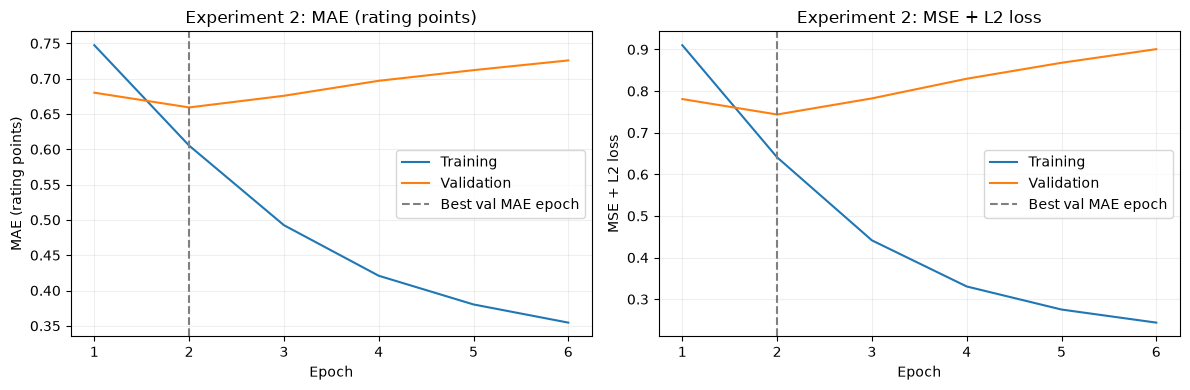

Completed 6 epochs; restored epoch 2. Best validation MAE: 0.659228. After the selected epoch, training MAE decreased while validation MAE increased: evidence of overfitting.

In [8]:
experiment_2_result = run_validation_experiment("Experiment 2", 16, 0.005)
experiment_results = [result for result in experiment_results if result["Experiment"] != "Experiment 2"]
experiment_results.append(experiment_2_result)

## Experiment 3: reduce learning rate

Return to 32 dimensions and use learning rate 0.001. All other settings remain unchanged. A smaller step size may learn more gradually. This is a fresh initialization, not further training of Experiment 1 or Experiment 2.

Epoch 1/30


276/276 - 1s - 5ms/step - loss: 1.0368 - mae: 0.8085 - val_loss: 0.9803 - val_mae: 0.7891


Epoch 2/30


276/276 - 1s - 2ms/step - loss: 0.9294 - mae: 0.7608 - val_loss: 0.8954 - val_mae: 0.7457


Epoch 3/30


276/276 - 1s - 2ms/step - loss: 0.7807 - mae: 0.6805 - val_loss: 0.8072 - val_mae: 0.6950


... (12 outputs left out)

Epoch 10/30


276/276 - 1s - 2ms/step - loss: 0.2392 - mae: 0.3360 - val_loss: 0.7991 - val_mae: 0.6845


,loss,mae,val_loss,val_mae
epoch,,,,
1,1.036751,0.808526,0.980293,0.789149
2,0.929376,0.760764,0.895446,0.745685
3,0.780710,0.680513,0.807161,0.694983
4,0.627525,0.594158,0.769550,0.674283
5,0.513783,0.527214,0.757455,0.667132
6,0.428042,0.472118,0.757753,0.666462
7,0.362396,0.427762,0.764658,0.669337
8,0.311515,0.391645,0.774644,0.673635
9,0.271326,0.361551,0.786432,0.678785


,Experiment,Embedding Dimension,Learning Rate,Batch Size,Epochs Completed,Best Epoch,Best Training MAE,Best Validation MAE,Best Validation Loss,Training MAE at Best Epoch,Validation Loss at Best Epoch
0,Experiment 3,32,0.001,256,10,6,0.335963,0.666462,0.757455,0.472118,0.757753


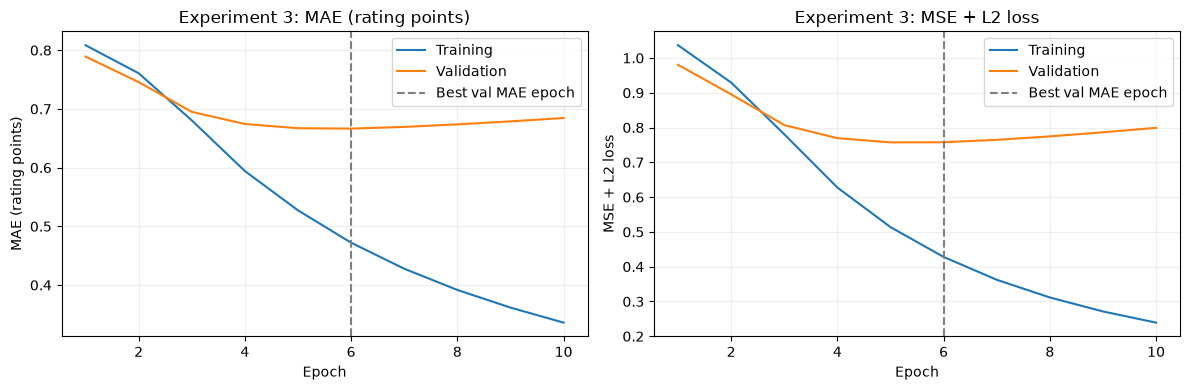

Completed 10 epochs; restored epoch 6. Best validation MAE: 0.666462. After the selected epoch, training MAE decreased while validation MAE increased: evidence of overfitting.

In [9]:
experiment_3_result = run_validation_experiment("Experiment 3", 32, 0.001)
experiment_results = [result for result in experiment_results if result["Experiment"] != "Experiment 3"]
experiment_results.append(experiment_3_result)

## Validation-only comparison and configuration selection

**Best Epoch** is the epoch with minimum validation MAE (the checkpoint restored by early stopping). **Best Training MAE** is the minimum training MAE across all epochs; **Best Validation Loss** is the minimum validation loss across all epochs. These minima may occur at different epochs. The extra “at Best Epoch” columns show the training MAE and validation loss at the selected checkpoint, avoiding confusion. Loss includes the unchanged L2 penalty.

Sort by validation MAE alone to identify the configuration to carry forward. Do not use any archived test results. Single-seed differences are descriptive, not a claim of statistical significance. This section ends without final test evaluation.

In [10]:
comparison = pd.DataFrame(experiment_results).sort_values(
    "Best Validation MAE", kind="stable"
).reset_index(drop=True)
assert set(comparison["Experiment"]) == {"Experiment 1", "Experiment 2", "Experiment 3"}
display(comparison)
selected_configuration = comparison.iloc[0].to_dict()
selected_name = selected_configuration["Experiment"]
# None if the original experiment wins: its weights were not retrained/recovered.
selected_model = experiment_models.get(selected_name)

display(Markdown(
    f"**Selected by validation MAE only: {selected_name}**, "
    f"{int(selected_configuration['Embedding Dimension'])} factors, "
    f"learning rate {selected_configuration['Learning Rate']}; "
    f"validation MAE **{selected_configuration['Best Validation MAE']:.6f}**. "
    "No test evaluation was run in this comparison."
))
base = comparison.set_index("Experiment").loc["Experiment 1"]
for name in ["Experiment 2", "Experiment 3"]:
    row = comparison.set_index("Experiment").loc[name]
    difference = row["Best Validation MAE"] - base["Best Validation MAE"]
    display(Markdown(
        f"**{name} versus Experiment 1:** validation MAE difference "
        f"{difference:+.6f} rating points (negative means lower error). "
        f"Selected epoch: {int(row['Best Epoch'])}; "
        f"training/validation MAE gap at that epoch: "
        f"{row['Best Validation MAE'] - row['Training MAE at Best Epoch']:.6f}."
    ))

,Experiment,Embedding Dimension,Learning Rate,Batch Size,Epochs Completed,Best Epoch,Best Training MAE,Best Validation MAE,Best Validation Loss,Training MAE at Best Epoch,Validation Loss at Best Epoch
0,Experiment 2,16,0.005,256,6,2,0.354510,0.659228,0.743684,0.605222,0.743684
1,Experiment 1,32,0.005,256,6,2,0.256033,0.665013,0.758456,0.572927,0.758456
2,Experiment 3,32,0.001,256,10,6,0.335963,0.666462,0.757455,0.472118,0.757753


**Selected by validation MAE only: Experiment 2**, 16 factors, learning rate 0.005; validation MAE **0.659228**. No test evaluation was run in this comparison.

**Experiment 2 versus Experiment 1:** validation MAE difference -0.005785 rating points (negative means lower error). Selected epoch: 2; training/validation MAE gap at that epoch: 0.054006.

**Experiment 3 versus Experiment 1:** validation MAE difference +0.001449 rating points (negative means lower error). Selected epoch: 6; training/validation MAE gap at that epoch: 0.194344.

### Stop here — final evaluation awaits your decision

The selected configuration is based only on validation MAE. Experiments 2 and 3 were freshly trained and their restored-weight models remain in `experiment_models` in this session. Saved notebook outputs retain histories and comparison results; they do not persist live model weights across a kernel restart. Experiment 1's historical weights were not reconstructed.

The original test results were already observed in earlier work and remain archived above. This comparison neither reruns nor uses them. A strictly independent final performance estimate would require an additional genuinely untouched holdout; otherwise disclose the previous exposure when reporting the existing test partition. No final test call is made here.

## Authorized recovery of Experiment 2 weights

The original experiment outputs above remain unchanged. Its training kernel closed without persisting weights, so you authorized **one identical retraining of Experiment 2 only**. The existing split, ID-mapping logic, seed, model builder, 16 factors, learning rate 0.005, batch size 256, maximum 30 epochs, L2 penalty, and early-stopping settings are reused. Neither Experiment 1 nor Experiment 3 is retrained. Selection is already fixed to Experiment 2, before test evaluation.

The recovery run's history and plots below identify the actual weights used for final evaluation. Save the restored model immediately so another kernel shutdown cannot lose it. Subsequent finalization does not call fit again.

Epoch 1/30


276/276 - 1s - 4ms/step - loss: 0.9101 - mae: 0.7474 - val_loss: 0.7808 - val_mae: 0.6801


Epoch 2/30


276/276 - 0s - 1ms/step - loss: 0.6408 - mae: 0.6052 - val_loss: 0.7437 - val_mae: 0.6592


Epoch 3/30


276/276 - 0s - 1ms/step - loss: 0.4413 - mae: 0.4925 - val_loss: 0.7824 - val_mae: 0.6757


... (4 outputs left out)

Epoch 6/30


276/276 - 0s - 1ms/step - loss: 0.2437 - mae: 0.3545 - val_loss: 0.9007 - val_mae: 0.7258


,loss,mae,val_loss,val_mae
epoch,,,,
1,0.910133,0.747357,0.780763,0.680130
2,0.640786,0.605222,0.743684,0.659228
3,0.441346,0.492508,0.782359,0.675743
4,0.330572,0.420904,0.829569,0.696954
5,0.275164,0.380250,0.867916,0.712026
6,0.243725,0.354510,0.900671,0.725825


,Experiment,Embedding Dimension,Learning Rate,Batch Size,Epochs Completed,Best Epoch,Best Training MAE,Best Validation MAE,Best Validation Loss,Training MAE at Best Epoch,Validation Loss at Best Epoch
0,Experiment 2,16,0.005,256,6,2,0.35451,0.659228,0.743684,0.605222,0.743684


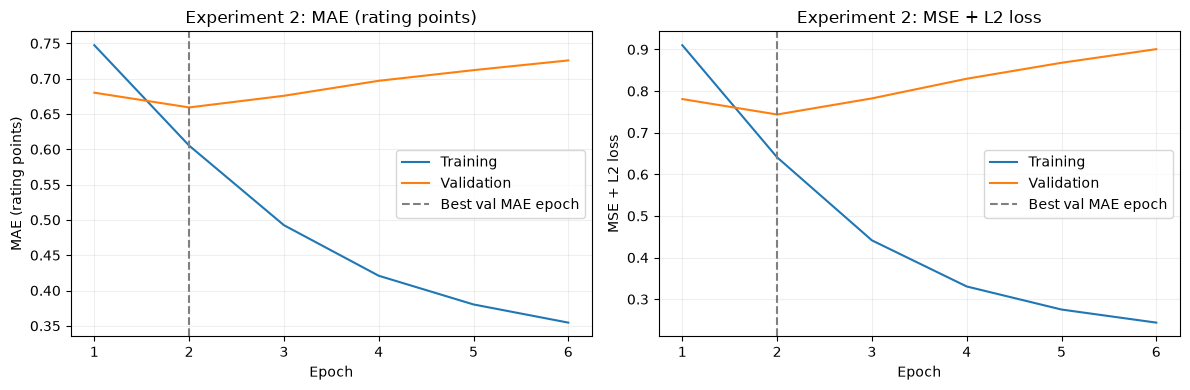

Completed 6 epochs; restored epoch 2. Best validation MAE: 0.659228. After the selected epoch, training MAE decreased while validation MAE increased: evidence of overfitting.

Recovered Experiment 2 restored weights saved before final evaluation.


In [8]:
recovery_result = run_validation_experiment("Experiment 2", 16, 0.005)
recovery_models_directory = project_root / "models"
recovery_models_directory.mkdir(parents=True, exist_ok=True)
experiment_models["Experiment 2"].save(recovery_models_directory / "movie_recommender.keras")
print("Recovered Experiment 2 restored weights saved before final evaluation.")

# Finalize the validation-selected Experiment 2

Experiment 2 was selected using **validation MAE only**, not the test results. It achieved the lowest validation MAE of the three configurations. Its EarlyStopping callback monitored `val_mae`, mode `min`, patience 4, with `restore_best_weights=True`; the live model from that run therefore contains the weights from the best validation epoch.

**Recovery provenance:** you authorized the identical Experiment 2 retraining recorded immediately above because the original kernel's weights were unavailable. The final evaluation and export use that recovery run's restored weights and actual history. The finalization cells themselves do not retrain. The guard below prevents evaluating or exporting the old 32-factor model.

Existing variables: `experiment_models["Experiment 2"]`, `experiment_histories["Experiment 2"]`; training inputs/targets `train_inputs`, `y_train`; validation inputs/targets `validation_inputs`, `y_validation`; held-out frame `test`, inputs `test_inputs`, targets `y_test`; mappings `user_to_index`, `movie_to_index`.

The final model remains Experiment 2 regardless of test performance. Earlier Experiment 1 test results are archived above: although this partition did not train the model or select between the three configurations, it was previously inspected, so it is not a completely never-seen holdout.

In [9]:
# Require the already-trained object. Never call build_model() or fit() here.
if "experiment_models" not in globals() or "Experiment 2" not in experiment_models:
    raise RuntimeError(
        "The trained Experiment 2 model is not in this kernel. Its saved notebook "
        "outputs cannot recover weights. Supply its original checkpoint and exact "
        "training mappings/history, or explicitly authorize retraining separately. "
        "No final evaluation or model export has run."
    )
if "experiment_histories" not in globals() or "Experiment 2" not in experiment_histories:
    raise RuntimeError("The actual Experiment 2 training history is required.")

final_model = experiment_models["Experiment 2"]
final_history = experiment_histories["Experiment 2"]
final_best_epoch = int(final_history["val_mae"].idxmin())
final_best_validation_mae = float(final_history.loc[final_best_epoch, "val_mae"])
assert final_model.get_layer("user_embedding").output_dim == 16
assert final_model.get_layer("movie_embedding").output_dim == 16
assert np.isclose(float(final_model.optimizer.learning_rate.numpy()), 0.005)
assert final_model.get_layer("user_embedding").input_dim == len(user_to_index)
assert final_model.get_layer("movie_embedding").input_dim == len(movie_to_index)
print(f"Selected: Experiment 2; best epoch: {final_best_epoch}")
print(f"Best validation MAE (full available precision): {final_best_validation_mae!r}")
display(final_history.loc[[final_best_epoch]])

Selected: Experiment 2; best epoch: 2
Best validation MAE (full available precision): 0.6592280864715576


,loss,mae,val_loss,val_mae
epoch,,,,
2,0.640786,0.605222,0.743684,0.659228


## Final test evaluation — selected model only

This section makes the first final test evaluation of **Experiment 2**, after its selection is fixed. It does not evaluate the other experiments. The partition was not used to fit Experiment 2 or choose the configuration. Previously archived Experiment 1 test exposure must still be disclosed.

**MAE** is the average absolute difference between predicted and actual ratings. For example, MAE 0.65 means predictions differ by about 0.65 rating points on average; that example is explanatory, not a measured result. **RMSE** also measures prediction error in rating points but penalizes large mistakes more heavily. MSE uses squared rating points. None is an accuracy percentage.

Use the same training-known test rows and original ID mappings. Cold-start test rows remain excluded as before. Final test predictions are clipped to [0.5, 5.0] before computing errors. Validation history remains unclipped because training and model selection are unchanged. Archived unclipped test metrics are retained at the end.

In [7]:
# Avoid accidentally repeating the full final evaluation in the same session.
if "final_test_predictions" in globals():
    raise RuntimeError("Final predictions already exist in this session; reuse the saved results below.")
assert len(test) == len(y_test) == len(test_inputs["user"]) == len(test_inputs["movie"])
assert test.userId.isin(user_to_index).all()
assert test.movieId.isin(movie_to_index).all()
np.testing.assert_array_equal(test_inputs["user"].ravel(), test.userId.map(user_to_index).to_numpy())
np.testing.assert_array_equal(test_inputs["movie"].ravel(), test.movieId.map(movie_to_index).to_numpy())
np.testing.assert_allclose(y_test.ravel(), test.rating.to_numpy())

final_test_dataset = make_dataset(test_inputs, y_test)
final_test_predictions_raw = final_model.predict(final_test_dataset, verbose=0).ravel()
final_test_predictions = np.clip(final_test_predictions_raw, 0.5, 5.0)
assert ((final_test_predictions >= 0.5) & (final_test_predictions <= 5.0)).all()
final_actual_ratings = y_test.ravel()
assert np.isfinite(final_test_predictions).all()
final_test_mae = float(np.mean(np.abs(final_test_predictions - final_actual_ratings)))
final_test_mse = float(np.mean((final_test_predictions - final_actual_ratings) ** 2))
final_test_rmse = float(np.sqrt(final_test_mse))
final_metrics = pd.DataFrame([{
    "Selected Model": "Experiment 2",
    "Prediction Policy": "Clipped to [0.5, 5.0]",
    "Best Validation MAE": final_best_validation_mae,
    "Test MAE": final_test_mae,
    "Test RMSE": final_test_rmse,
    "Test MSE": final_test_mse,
    "Test Rows Evaluated": len(test),
    "Cold-start Test Rows Excluded": len(test_raw) - len(test),
}])
display(final_metrics)
final_validation_test_gap = final_test_mae - final_best_validation_mae
display(Markdown(
    f"Test MAE differs from best validation MAE by **{final_validation_test_gap:+.4f} rating points** "
    f"(absolute difference {abs(final_validation_test_gap):.4f}). "
    "Validation MAE is the original unclipped training metric; test MAE uses clipped predictions. Compare the magnitude with the rating scale; this single split provides no uncertainty estimate. "
    "These descriptive results do not justify a claim of universally good recommendations. "
    "Experiment 2 remains selected; no configuration is changed using test results."
))

,Selected Model,Prediction Policy,Best Validation MAE,Test MAE,Test RMSE,Test MSE,Test Rows Evaluated,Cold-start Test Rows Excluded
0,Experiment 2,"Clipped to [0.5, 5.0]",0.659228,0.663035,0.863957,0.746422,14466,660


Test MAE differs from best validation MAE by **+0.0038 rating points** (absolute difference 0.0038). Validation MAE is the original unclipped training metric; test MAE uses clipped predictions. Compare the magnitude with the rating scale; this single split provides no uncertainty estimate. These descriptive results do not justify a claim of universally good recommendations. Experiment 2 remains selected; no configuration is changed using test results.

## Interpret ten test predictions

The first ten rows of the fixed test partition are shown rather than hand-picked successes. Join movie titles by `movieId`, preserving distinct records with duplicate titles. These examples are for interpretation only and do not change the model.

In [8]:
final_prediction_examples = test[["userId", "movieId", "rating"]].copy()
final_prediction_examples = final_prediction_examples.rename(columns={"rating": "actual_rating"})
final_prediction_examples["predicted_rating"] = final_test_predictions
final_prediction_examples["absolute_error"] = np.abs(final_test_predictions - final_actual_ratings)
final_prediction_examples = final_prediction_examples.merge(
    movies[["movieId", "title"]], on="movieId", how="left", validate="many_to_one"
)
display(final_prediction_examples[["userId", "movieId", "title", "actual_rating",
                                   "predicted_rating", "absolute_error"]].head(10).round(3))

,userId,movieId,title,actual_rating,predicted_rating,absolute_error
0,432,77866,Robin Hood (2010),4.5,3.387,1.113
1,288,474,In the Line of Fire (1993),3.0,3.494,0.494
2,599,4351,Point Break (1991),3.0,2.176,0.824
3,42,2987,Who Framed Roger Rabbit? (1988),4.0,4.034,0.034
4,75,1610,"Hunt for Red October, The (1990)",4.0,3.182,0.818
5,51,177,Lord of Illusions (1995),4.0,3.411,0.589
6,354,51662,300 (2007),3.5,3.648,0.148
7,416,750,Dr. Strangelove or: How I Learned to Stop Worr...,4.5,3.480,1.020
8,438,6503,Charlie's Angels: Full Throttle (2003),0.5,2.775,2.275
9,73,8641,Anchorman: The Legend of Ron Burgundy (2004),3.5,3.901,0.401


## Personalized recommendations from the final model

This adapts the previous recommendation logic to explicitly use `final_model`, rather than the old global `model`. All rated movies are excluded, including recorded held-out interactions. Only movies with training-known IDs can be predicted. Scores are clipped to [0.5, 5.0] before ranking, and ties use movieId. Clipping may create ties at the boundaries. Visual inspection is not a ranking-quality evaluation and does not trigger retraining.

In [9]:
def recommend_final_for_user(user_id):
    if user_id not in user_to_index:
        raise ValueError("Choose a userId with a trained user embedding.")
    rated_ids = set(ratings.loc[ratings.userId == user_id, "movieId"])
    candidates = movies[
        movies.movieId.isin(movie_to_index) & ~movies.movieId.isin(rated_ids)
    ].copy()
    if candidates.empty:
        return pd.DataFrame(columns=["movieId", "title", "genres", "predicted_rating"])
    candidate_inputs = {
        "user": np.full((len(candidates), 1), user_to_index[user_id], dtype="int32"),
        "movie": candidates.movieId.map(movie_to_index).to_numpy(dtype="int32").reshape(-1, 1),
    }
    batch_predictions = []
    for start in range(0, len(candidates), BATCH_SIZE):
        batch = {key: values[start:start + BATCH_SIZE] for key, values in candidate_inputs.items()}
        batch_predictions.append(final_model(batch, training=False).numpy().ravel())
    candidates["predicted_rating"] = np.clip(np.concatenate(batch_predictions), 0.5, 5.0)
    assert candidates.predicted_rating.between(0.5, 5.0).all()
    return candidates.sort_values(
        ["predicted_rating", "movieId"], ascending=[False, True]
    ).head(10).reset_index(drop=True)

for user_id in sorted(user_to_index)[:3]:
    final_recommendations = recommend_final_for_user(user_id)
    assert final_recommendations.movieId.is_unique
    assert not final_recommendations.movieId.isin(
        ratings.loc[ratings.userId == user_id, "movieId"]
    ).any()
    print(f"Final model recommendations for user {user_id}")
    display(final_recommendations.round({"predicted_rating": 3}))

Final model recommendations for user 1


,movieId,title,genres,predicted_rating
0,858,"Godfather, The (1972)",Crime|Drama,5.000
1,912,Casablanca (1942),Drama|Romance,5.000
2,1283,High Noon (1952),Drama|Western,5.000
3,3451,Guess Who's Coming to Dinner (1967),Drama,5.000
4,105504,Captain Phillips (2013),Adventure|Drama|Thriller|IMAX,5.000
5,904,Rear Window (1954),Mystery|Thriller,4.975
6,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.973
7,4995,"Beautiful Mind, A (2001)",Drama|Romance,4.971
8,2186,Strangers on a Train (1951),Crime|Drama|Film-Noir|Thriller,4.944
9,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.937


Final model recommendations for user 2


,movieId,title,genres,predicted_rating
0,110,Braveheart (1995),Action|Drama|War,4.332
1,88125,Harry Potter and the Deathly Hallows: Part 2 (...,Action|Adventure|Drama|Fantasy|Mystery|IMAX,4.279
2,2329,American History X (1998),Crime|Drama,4.261
3,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.254
4,225,Disclosure (1994),Drama|Thriller,4.176
5,364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,4.174
6,377,Speed (1994),Action|Romance|Thriller,4.171
7,8665,"Bourne Supremacy, The (2004)",Action|Crime|Thriller,4.160
8,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.128
9,4963,Ocean's Eleven (2001),Crime|Thriller,4.127


Final model recommendations for user 3


,movieId,title,genres,predicted_rating
0,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.031
1,858,"Godfather, The (1972)",Crime|Drama,3.995
2,60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi,3.956
3,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,3.950
4,1204,Lawrence of Arabia (1962),Adventure|Drama|War,3.943
5,1411,Hamlet (1996),Crime|Drama|Romance,3.932
6,5618,Spirited Away (Sen to Chihiro no kamikakushi) ...,Adventure|Animation|Fantasy,3.925
7,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,3.923
8,93510,21 Jump Street (2012),Action|Comedy|Crime,3.909
9,111617,Blended (2014),Comedy,3.905


## Save the selected model and exact training mappings

`project_root / "models"` resolves correctly from either the project directory or `notebooks/` (equivalent to `../models` from this notebook). Save only Experiment 2; no new model or mappings are generated.

JSON object keys are strings, so raw NumPy integer IDs are converted to integer-form strings and encoded indexes to Python integers. On loading, convert both back with `{int(key): int(value) ...}`. The model's embedding row order must always use these saved mappings, never a newly generated dictionary.

In [13]:
import json

models_directory = project_root / "models"
models_directory.mkdir(parents=True, exist_ok=True)
final_model_path = models_directory / "movie_recommender.keras"
user_mapping_path = models_directory / "user_to_index.json"
movie_mapping_path = models_directory / "movie_to_index.json"

# Write the actual existing mapping values, not a newly fitted encoding.
user_mapping_payload = {str(int(key)): int(value) for key, value in user_to_index.items()}
movie_mapping_payload = {str(int(key)): int(value) for key, value in movie_to_index.items()}
final_model.save(final_model_path)
user_mapping_path.write_text(json.dumps(user_mapping_payload, indent=2) + "\n")
movie_mapping_path.write_text(json.dumps(movie_mapping_payload, indent=2) + "\n")
for saved_path in [final_model_path, user_mapping_path, movie_mapping_path]:
    assert saved_path.is_file() and saved_path.stat().st_size > 0
    print("Saved:", saved_path.relative_to(project_root))

Saved: models/movie_recommender.keras
Saved: models/user_to_index.json
Saved: models/movie_to_index.json


## Verify model and mapping round-trip

Load into a new variable and compare a small sample of test-pair predictions with the in-memory Experiment 2 model. This checks serialization, not model selection, and does not repeat full test evaluation. Reloaded mappings must equal the original training dictionaries.

In [10]:
reloaded_final_model = keras.models.load_model(final_model_path)
loaded_user_to_index = {int(key): int(value) for key, value in json.loads(user_mapping_path.read_text()).items()}
loaded_movie_to_index = {int(key): int(value) for key, value in json.loads(movie_mapping_path.read_text()).items()}
assert loaded_user_to_index == user_to_index
assert loaded_movie_to_index == movie_to_index

sample_inputs = {name: values[:10] for name, values in test_inputs.items()}
in_memory_sample = final_model(sample_inputs, training=False).numpy().ravel()
reloaded_sample = reloaded_final_model(sample_inputs, training=False).numpy().ravel()
np.testing.assert_allclose(in_memory_sample, reloaded_sample, rtol=1e-5, atol=1e-6)
display(pd.DataFrame({"In-memory Prediction": in_memory_sample,
                      "Reloaded Prediction": reloaded_sample,
                      "Absolute Difference": np.abs(in_memory_sample - reloaded_sample)}))
print("Saved model predictions match; both exact ID mappings round-tripped successfully.")

,In-memory Prediction,Reloaded Prediction,Absolute Difference
0,3.387330,3.387330,0.0
1,3.494497,3.494497,0.0
2,2.176052,2.176052,0.0
3,4.034109,4.034109,0.0
4,3.181856,3.181856,0.0
5,3.410743,3.410743,0.0
6,3.647698,3.647698,0.0
7,3.479510,3.479510,0.0
8,2.774975,2.774975,0.0
9,3.901303,3.901303,0.0


Saved model predictions match; both exact ID mappings round-tripped successfully.


## Final Model Summary

The following Markdown report is populated from the actual Experiment 2 training history and final test predictions. If the trained model is unavailable, execution stops at the availability check; no numerical final results are guessed.

In [11]:
final_summary = f"""
### Final Model Summary — executed results

- **Algorithm:** neural-network collaborative filtering using user/movie embeddings, dot product, user/movie biases, and a fixed training mean.
- **Selected experiment:** Experiment 2; selected using validation MAE only, not test performance.
- **Embedding dimension:** {final_model.get_layer('user_embedding').output_dim}.
- **Learning rate:** {float(final_model.optimizer.learning_rate.numpy()):.3f}; **batch size:** {BATCH_SIZE}; **maximum epochs:** {MAX_EPOCHS}.
- **Early stopping:** validation MAE, mode min, patience 4, restore_best_weights=True.
- **Epochs completed:** {len(final_history)}; **best epoch:** {final_best_epoch}.
- **Training MAE at best epoch:** {float(final_history.loc[final_best_epoch, 'mae']):.6f}.
- **Best validation MAE:** {final_best_validation_mae:.6f} rating points.
- **Final test MAE:** {final_test_mae:.6f} rating points.
- **Final test RMSE:** {final_test_rmse:.6f} rating points; **MSE:** {final_test_mse:.6f}.
- **Test scope:** {len(test):,} training-known interactions; {len(test_raw)-len(test):,} cold-start interactions excluded. Test predictions and recommendation scores are clipped to [0.5, 5.0]; validation history remains the original unclipped metric.
- **Loss:** Mean Squared Error with unchanged L2 regularization; **optimizer:** Adam.
- **Main challenge:** overfitting after the best epoch: training MAE continued improving while validation MAE worsened.
- **Why Experiment 2:** lowest validation MAE among the three configurations. It had a smaller training/validation gap at its selected epoch than Experiment 3, whose lower training error did not improve validation performance. This is descriptive evidence, not a statistical significance claim.
- **Test interpretation:** test-minus-validation MAE difference {final_validation_test_gap:+.6f}. Test results do not change the selected experiment. The split was not used to train Experiment 2 or select between configurations, but earlier Experiment 1 test exposure is disclosed.
- **Saved artifacts:** `models/movie_recommender.keras`, `models/user_to_index.json`, and `models/movie_to_index.json`; model reload predictions and mapping equality verified.
"""
display(Markdown(final_summary))


### Final Model Summary — executed results

- **Algorithm:** neural-network collaborative filtering using user/movie embeddings, dot product, user/movie biases, and a fixed training mean.
- **Selected experiment:** Experiment 2; selected using validation MAE only, not test performance.
- **Embedding dimension:** 16.
- **Learning rate:** 0.005; **batch size:** 256; **maximum epochs:** 30.
- **Early stopping:** validation MAE, mode min, patience 4, restore_best_weights=True.
- **Epochs completed:** 6; **best epoch:** 2.
- **Training MAE at best epoch:** 0.605222.
- **Best validation MAE:** 0.659228 rating points.
- **Final test MAE:** 0.663035 rating points.
- **Final test RMSE:** 0.863957 rating points; **MSE:** 0.746422.
- **Test scope:** 14,466 training-known interactions; 660 cold-start interactions excluded. Test predictions and recommendation scores are clipped to [0.5, 5.0]; validation history remains the original unclipped metric.
- **Loss:** Mean Squared Error with unchanged L2 regularization; **optimizer:** Adam.
- **Main challenge:** overfitting after the best epoch: training MAE continued improving while validation MAE worsened.
- **Why Experiment 2:** lowest validation MAE among the three configurations. It had a smaller training/validation gap at its selected epoch than Experiment 3, whose lower training error did not improve validation performance. This is descriptive evidence, not a statistical significance claim.
- **Test interpretation:** test-minus-validation MAE difference +0.003807. Test results do not change the selected experiment. The split was not used to train Experiment 2 or select between configurations, but earlier Experiment 1 test exposure is disclosed.
- **Saved artifacts:** `models/movie_recommender.keras`, `models/user_to_index.json`, and `models/movie_to_index.json`; model reload predictions and mapping equality verified.


## Historical final metrics before clipping

The following previously executed metrics used **unclipped** predictions. They are retained for provenance; the refreshed final evaluation above applies `np.clip(predictions, 0.5, 5.0)`. Training and validation selection remain unchanged.

```text
  Selected Model  Best Validation MAE  Test MAE  Test RMSE  Test MSE  \
0   Experiment 2             0.659228  0.663247   0.864017  0.746526   

   Test Rows Evaluated  Cold-start Test Rows Excluded  
0                14466                            660  
```